# 04 - Data Enrichment: adding neighbourhood features

**Goal:** add the scraped Inside Airbnb information to the Kaggle dataset.

**The challenge:** the Kaggle rows have no listing ID, so they cannot be matched one-to-one with Inside Airbnb listings.
Both datasets do have **coordinates**, so we match them at the **neighbourhood** level:

1. Summarise the Inside Airbnb listings per neighbourhood (median reviews, average rating, share of superhosts, ...).
2. Use the neighbourhood boundaries (`neighbourhoods.geojson`) to find which neighbourhood each Kaggle listing is in.
3. Merge the neighbourhood summary onto every Kaggle listing.

**Limitation:** the Inside Airbnb snapshot is more recent than the Kaggle data. Neighbourhood-level characteristics
change slowly, so they are used as a description of the area, not of the individual listing.

## Step 1: Load the data

In [4]:
import json
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED = Path("../data/processed")
EXTERNAL = Path("../data/external/insideairbnb")

df = pd.read_csv(PROCESSED / "airbnb_master_raw.csv").drop(columns=["Unnamed: 0"])
sources = pd.read_csv(EXTERNAL / "sources.csv")

print("Kaggle rows:", df.shape)
print("Cities with Inside Airbnb files:", sources["city"].nunique(), "/ 10")

Kaggle rows: (51707, 21)
Cities with Inside Airbnb files: 10 / 10


## Step 2: Summarise Inside Airbnb listings per neighbourhood
- `amenities` is stored as text like `["Wifi", "Kitchen", ...]`, so we parse it and count the items.
- `host_is_superhost` is stored as `t` / `f`, so we convert it to 1 / 0.
- The Inside Airbnb `price` column is **not** used: it is in each country's local currency and describes a different time period.

In [5]:
LISTING_COLS = [
    "neighbourhood_cleansed", "room_type", "amenities", "number_of_reviews",
    "review_scores_rating", "host_is_superhost", "host_listings_count", "availability_365",
]


def count_amenities(text):
    try:
        return len(json.loads(text))
    except (TypeError, ValueError):
        return np.nan


def neighbourhood_features(listings_path):
    listings = pd.read_csv(listings_path, usecols=LISTING_COLS, low_memory=False)
    listings["amenities_count"] = listings["amenities"].apply(count_amenities)
    listings["is_superhost"] = listings["host_is_superhost"].map({"t": 1, "f": 0})
    listings["is_entire_home"] = (listings["room_type"] == "Entire home/apt").astype(int)

    summary = listings.groupby("neighbourhood_cleansed").agg(
        nb_listings=("room_type", "size"),
        nb_median_reviews=("number_of_reviews", "median"),
        nb_avg_rating=("review_scores_rating", "mean"),
        nb_superhost_share=("is_superhost", "mean"),
        nb_median_amenities=("amenities_count", "median"),
        nb_median_availability=("availability_365", "median"),
        nb_avg_host_listings=("host_listings_count", "mean"),
        nb_entire_home_share=("is_entire_home", "mean"),
    )
    return summary.reset_index().rename(columns={"neighbourhood_cleansed": "neighbourhood"})

## Step 3: Find the neighbourhood of every Kaggle listing
- Each Kaggle listing becomes a **point** from its `lng` / `lat`.
- A **spatial join** checks which neighbourhood polygon contains each point.
- A few points can fall just outside every polygon (for example on the edge of the city).
  Those get the **nearest** neighbourhood instead, and we record the distance so we can check it.
- EPSG:3035 is a map projection in metres for Europe, needed to measure distances correctly.

In [6]:
def assign_neighbourhoods(points_df, geojson_path):
    polygons = gpd.read_file(geojson_path)[["neighbourhood", "geometry"]].to_crs("EPSG:4326")
    points = gpd.GeoDataFrame(
        index=points_df.index,
        geometry=gpd.points_from_xy(points_df["lng"], points_df["lat"]),
        crs="EPSG:4326",
    )

    inside = gpd.sjoin(points, polygons, how="left", predicate="within")
    inside = inside[~inside.index.duplicated(keep="first")]  # a point on a border can touch 2 polygons

    result = pd.DataFrame(index=points_df.index)
    result["neighbourhood"] = inside["neighbourhood"]
    result["nb_match_method"] = np.where(result["neighbourhood"].notna(), "inside", None)
    result["nb_distance_m"] = 0.0

    outside = result["neighbourhood"].isna()
    if outside.any():
        nearest = gpd.sjoin_nearest(
            points[outside].to_crs("EPSG:3035"),
            polygons.to_crs("EPSG:3035"),
            how="left",
            distance_col="distance_m",
        )
        nearest = nearest[~nearest.index.duplicated(keep="first")]
        result.loc[nearest.index, "neighbourhood"] = nearest["neighbourhood"]
        result.loc[nearest.index, "nb_match_method"] = "nearest"
        result.loc[nearest.index, "nb_distance_m"] = nearest["distance_m"]

    return result

## Step 4: Run both steps for every city

In [7]:
neighbourhood_tables = []
assignments = []

for city in sorted(df["city"].unique()):
    files = sources[sources["city"] == city.lower()].set_index("file")["local_path"]
    if "data/listings.csv.gz" not in files or "visualisations/neighbourhoods.geojson" not in files:
        print(f"{city:<10} skipped: Inside Airbnb files not found")
        continue

    features = neighbourhood_features(files["data/listings.csv.gz"])
    features.insert(0, "city", city)
    neighbourhood_tables.append(features)

    city_rows = df[df["city"] == city]
    assignments.append(assign_neighbourhoods(city_rows, files["visualisations/neighbourhoods.geojson"]))
    print(f"{city:<10} {len(features):>3} neighbourhoods, {len(city_rows):>5} Kaggle listings assigned")

neighbourhoods = pd.concat(neighbourhood_tables, ignore_index=True)
assigned = pd.concat(assignments)

df = df.join(assigned)  # joins on the index, so every row gets its own neighbourhood

Amsterdam   22 neighbourhoods,  2080 Kaggle listings assigned
Athens      44 neighbourhoods,  5280 Kaggle listings assigned
Barcelona   68 neighbourhoods,  2833 Kaggle listings assigned
Berlin     137 neighbourhoods,  2484 Kaggle listings assigned
Budapest    23 neighbourhoods,  4022 Kaggle listings assigned
Lisbon     130 neighbourhoods,  5763 Kaggle listings assigned
London      33 neighbourhoods,  9993 Kaggle listings assigned
Paris       20 neighbourhoods,  6688 Kaggle listings assigned
Rome        15 neighbourhoods,  9027 Kaggle listings assigned
Vienna      23 neighbourhoods,  3537 Kaggle listings assigned


## Step 5: Check the neighbourhood assignment
Most listings should fall inside a neighbourhood. Listings matched by "nearest" should be close (a few hundred metres).

In [8]:
print(pd.crosstab(df["city"], df["nb_match_method"].fillna("not assigned"), margins=True))
print()
print(df.loc[df["nb_match_method"] == "nearest", "nb_distance_m"].describe().round(0))

nb_match_method  inside  nearest    All
city                                   
Amsterdam          2073        7   2080
Athens             5276        4   5280
Barcelona          2831        2   2833
Berlin             2484        0   2484
Budapest           4022        0   4022
Lisbon             5763        0   5763
London             9955       38   9993
Paris              6688        0   6688
Rome               9027        0   9027
Vienna             3537        0   3537
All               51656       51  51707

count     51.0
mean      67.0
std      161.0
min        0.0
25%        4.0
50%        8.0
75%       61.0
max      809.0
Name: nb_distance_m, dtype: float64


## Step 6: Merge the neighbourhood features onto the Kaggle listings
`validate="many_to_one"` makes pandas raise an error if a (city, neighbourhood) pair appears twice in the
neighbourhood table. Without it, a duplicate key would silently create extra rows.

In [9]:
enriched = df.merge(neighbourhoods, on=["city", "neighbourhood"], how="left", validate="many_to_one")

print("Rows before:", len(df))
print("Rows after: ", len(enriched))
print("Same number of rows:", len(df) == len(enriched))

nb_cols = [c for c in neighbourhoods.columns if c.startswith("nb_")]
print("\nNew columns:", nb_cols)
print("\nMissing values in the new columns (%):")
print((enriched[nb_cols].isna().mean() * 100).round(2))

Rows before: 51707
Rows after:  51707
Same number of rows: True

New columns: ['nb_listings', 'nb_median_reviews', 'nb_avg_rating', 'nb_superhost_share', 'nb_median_amenities', 'nb_median_availability', 'nb_avg_host_listings', 'nb_entire_home_share']

Missing values in the new columns (%):
nb_listings               0.01
nb_median_reviews         0.01
nb_avg_rating             0.02
nb_superhost_share        0.01
nb_median_amenities       0.01
nb_median_availability    0.01
nb_avg_host_listings      0.01
nb_entire_home_share      0.01
dtype: float64


## Step 7: Did the new features improve the correlation with price?
Same method as notebook 02: extreme outliers (> 30x city median) are excluded first.

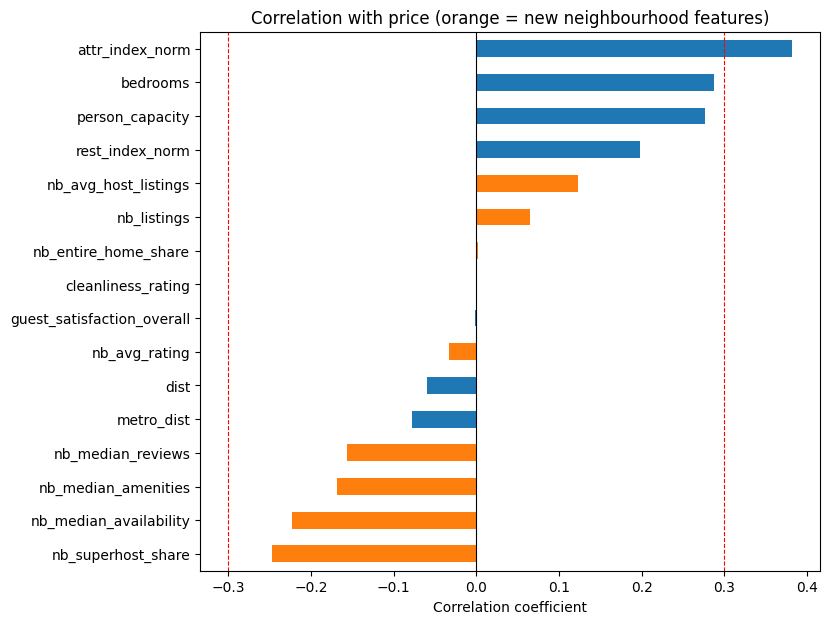

nb_superhost_share           -0.247
nb_median_availability       -0.223
nb_median_amenities          -0.168
nb_median_reviews            -0.156
metro_dist                   -0.078
dist                         -0.060
nb_avg_rating                -0.034
guest_satisfaction_overall   -0.001
cleanliness_rating            0.001
nb_entire_home_share          0.002
nb_listings                   0.065
nb_avg_host_listings          0.123
rest_index_norm               0.198
person_capacity               0.277
bedrooms                      0.287
attr_index_norm               0.382
dtype: float64

In [10]:
check = enriched.copy()
check["price_vs_city_median"] = check["realSum"] / check.groupby("city")["realSum"].transform("median")
check = check[check["price_vs_city_median"] <= 30]

old_cols = ["person_capacity", "bedrooms", "dist", "metro_dist", "attr_index_norm", "rest_index_norm",
            "cleanliness_rating", "guest_satisfaction_overall"]
corr = check[old_cols + nb_cols].corrwith(check["realSum"]).sort_values()

colors = ["tab:orange" if c in nb_cols else "tab:blue" for c in corr.index]
plt.figure(figsize=(8, 7))
corr.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(0.3, color="red", linestyle="--", linewidth=0.8)
plt.axvline(-0.3, color="red", linestyle="--", linewidth=0.8)
plt.title("Correlation with price (orange = new neighbourhood features)")
plt.xlabel("Correlation coefficient")
plt.show()

corr.round(3)

## Step 8: Save
- `airbnb_enriched.csv`: every Kaggle listing with its neighbourhood and the neighbourhood features.
- `neighbourhood_features.csv`: one row per neighbourhood (this becomes its own table in SQL later).

In [11]:
enriched.to_csv(PROCESSED / "airbnb_enriched.csv", index=False)
neighbourhoods.to_csv(PROCESSED / "neighbourhood_features.csv", index=False)
print("Saved:", enriched.shape, "and", neighbourhoods.shape)

Saved: (51707, 32) and (515, 10)


## Conclusions
1. All 51,707 listings were assigned a neighbourhood: 99.9% fall inside a neighbourhood boundary,
   51 listings were matched to the nearest neighbourhood (median distance 8 m, max 809 m).
2. The merge kept the row count unchanged (51,707). About 0.01% of rows have missing neighbourhood features.
3. Eight neighbourhood-level features were added. None exceeds |0.3| correlation with price, but the strongest
   (`nb_superhost_share` -0.25, `nb_median_availability` -0.22) are stronger than several original features
   such as `dist` and `metro_dist`.
4. Lower availability (higher demand) is associated with higher prices, which is consistent with expectations.
   Other relationships (e.g. superhost share) are possible explanations, not proven causes.
5. Correlations remain weak partly because prices differ strongly between cities; per-city analysis follows in the EDA.